# Day 10 · 모델링 드릴 (AI 모델링 40점)
AICE 2주 합격 플랜 · 영상 10편. 1~10번은 영상 문항, 11~15번은 추가 문항입니다.
- 형식: 빈칸 채우기 · 오류 정정 · 출력 예측. 빈칸은 밑줄 자리에 코드를 바로 채워 넣고 실행합니다.
- 이 노트북은 **해설**입니다.

_최종 수정 2026-10-20 · 바뀐 내용은 [안내 페이지의 업데이트 기록](https://pm-ainote.github.io/aice/#updates) · 개인 학습용, 재배포·판매 금지_

### 준비: 연습 데이터 내려받기
아래 셀을 먼저 실행하세요. 같은 폴더에 `aice_practice.csv` 가 생깁니다.

In [1]:
!wget -q -O aice_practice.csv https://raw.githubusercontent.com/pm-ainote/aice/main/data/aice_practice.csv
import os
print('준비 완료' if os.path.exists('aice_practice.csv') and os.path.getsize('aice_practice.csv') > 0 else '내려받기 실패: 이 셀을 다시 실행하세요')

준비 완료


### 준비 (실행만 하세요)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
df = pd.read_csv('aice_practice.csv')
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df = pd.get_dummies(data=df, columns=['Sex', 'Embarked'])
X = df.drop('Survived', axis=1)
y = df['Survived']

## 1. [출력 예측] test_size = 검증용 비율

In [3]:
# 결과: (150, 8)   (test_size = 검증용 비율)
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=7, stratify=y)
X_valid.shape

(150, 8)

## 2. [빈칸] stratify=y

In [4]:
# 정답 (stratify=y):
#   train_test_split(X, y, test_size=0.3, random_state=7, stratify=y)
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=7, stratify=y)
round(y_valid.mean(), 2)

np.float64(0.45)

## 3. [오류 정정] fit 먼저, 그다음 transform

In [5]:
# 정답 (fit 먼저, 그다음 transform):
#   ss = StandardScaler()
#   X_train = ss.fit_transform(X_train)
#   X_valid = ss.transform(X_valid)
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=7, stratify=y)
ss = StandardScaler()
X_train = ss.fit_transform(X_train)
X_valid = ss.transform(X_valid)

## 4. [오류 정정] 설정 이름은 철자까지 정확히

In [6]:
# 정답 (설정 이름은 철자까지 정확히):
#   param_grid = {'max_depth': [3, 5, 7]}
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=7, stratify=y)
GridSearchCV(DecisionTreeClassifier(), {'max_depth': [3, 5, 7]}, cv=3).fit(X_train, y_train)

GridSearchCV(cv=3, estimator=DecisionTreeClassifier(),
             param_grid={'max_depth': [3, 5, 7]})

## 5. [빈칸] best_params_ = 설정값, best_estimator_ = 모델

In [7]:
# 정답 (best_params_ = 설정값, best_estimator_ = 모델):
#   gs.best_params_
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=7, stratify=y)
gs = GridSearchCV(DecisionTreeClassifier(random_state=7), {'max_depth': [3, 5, 7, 10]}, cv=3).fit(X_train, y_train)
gs.best_params_

{'max_depth': 3}

## 6. [오류 정정] predict 에는 X, 정답 y 는 채점할 때

In [8]:
# 정답 (predict 에는 X, 정답 y 는 채점할 때):
#   dt.predict(X_valid)
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=7, stratify=y)
dt = DecisionTreeClassifier(random_state=7)
dt.fit(X_train, y_train)
dt.predict(X_valid)

array([1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1,
       0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0,
       1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0,
       0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1,
       0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0,
       0, 0, 0, 1])

## 7. [출력 예측] 정확도 = 맞힌 개수 / 전체

In [9]:
# 정답 (정확도 = 맞힌 개수 / 전체):
#   0.75
accuracy_score([1, 0, 1, 1], [1, 0, 0, 1])

0.75

## 8. [빈칸] 둘 중 하나 = binary_crossentropy

In [10]:
# 정답 (둘 중 하나 = binary_crossentropy):
#   loss='binary_crossentropy'
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical
model = Sequential([Dense(8, activation='relu', input_dim=8), Dense(2, activation='sigmoid')])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.loss

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


'binary_crossentropy'

## 9. [빈칸] val_ = 검증용

In [11]:
# 정답 (val_ = 검증용):
#   EarlyStopping(monitor='val_loss', patience=5)
from tensorflow.keras.callbacks import EarlyStopping
EarlyStopping(monitor='val_loss', patience=5).monitor

'val_loss'

## 10. [오류 정정] 기록 이름 = compile 의 metrics 이름

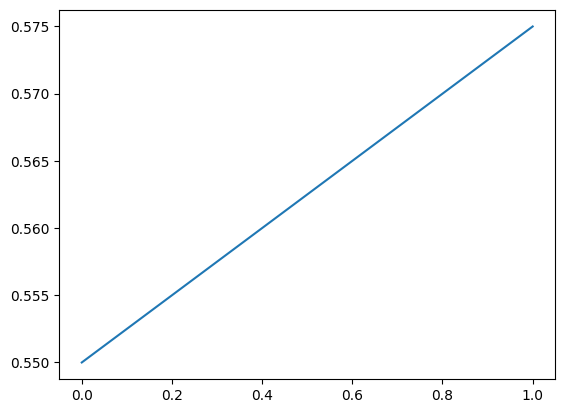

In [12]:
# 정답 (기록 이름 = compile 의 metrics 이름):
#   plt.plot(history.history['val_accuracy'])
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical
model = Sequential([Dense(8, activation='relu', input_dim=8), Dense(2, activation='sigmoid')])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history = model.fit(X.astype(float), to_categorical(y), epochs=2, validation_split=0.2, verbose=0)
plt.plot(history.history['val_accuracy'])

## 11. [빈칸] (추가) 정답 컬럼 빼기 = axis=1

In [13]:
# 정답 (정답 컬럼 빼기 = axis=1):
#   X = df.drop('Survived', axis=1)
X = df.drop('Survived', axis=1)
X.shape[1]

8

## 12. [출력 예측] (추가) 600 × 0.7 = 420

In [14]:
# 정답 (600 × 0.7 = 420):
#   420
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=7, stratify=y)
len(X_train)

420

## 13. [오류 정정] (추가) 정답과 예측 둘 다 넣는다

In [15]:
# 정답 (정답과 예측 둘 다 넣는다):
#   accuracy_score(y_valid, y_pred)
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=7, stratify=y)
from sklearn.metrics import accuracy_score
dt = DecisionTreeClassifier(random_state=7).fit(X_train, y_train)
y_pred = dt.predict(X_valid)
accuracy_score(y_valid, y_pred)

0.5444444444444444

## 14. [빈칸] (추가) 변수 중요도 = feature_importances_

In [16]:
# 정답 (변수 중요도 = feature_importances_):
#   gs.best_estimator_.feature_importances_
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=7, stratify=y)
gs = GridSearchCV(DecisionTreeClassifier(random_state=7), {'max_depth': [3, 5]}, cv=3).fit(X_train, y_train)
len(gs.best_estimator_.feature_importances_)

8

## 15. [출력 예측] (추가) 정답 3개 → 자리 2개씩

In [17]:
# 정답 (정답 3개 → 자리 2개씩):
#   (3, 2)
from tensorflow.keras.utils import to_categorical
to_categorical([0, 1, 1]).shape

(3, 2)